In [1]:
from IPython.display import display, HTML
display(HTML("<style>.container { width:82% !important; }</style>"))

In [1]:
# ============================================================
# Imports
# ============================================================
# Standard numerical and table-handling packages
import numpy as np
import pandas as pd

# Plotting and visualization
import matplotlib.pyplot as plt
from matplotlib import gridspec
from matplotlib.ticker import AutoMinorLocator

# General utilities
import pickle
import time
import copy
import random
import os
import glob
import shutil
from pathlib import Path
from dataclasses import dataclass
from multiprocessing import Pool
import subprocess
import warnings

# Astropy tools for statistics, FITS I/O, WCS, cutouts, and visualization
from astropy.stats import sigma_clip, sigma_clipped_stats
from astropy.io import fits
from astropy.nddata import Cutout2D
from astropy.utils.data import download_file
from astropy.wcs import WCS
from astropy.visualization import ZScaleInterval, ImageNormalize, AsinhStretch
from astropy.modeling.functional_models import Sersic1D, Sersic2D

# Image processing
import skimage
from skimage.transform import resize

# ============================================================
# Custom MC2fit modules
# Repository: https://github.com/galaxydiver/MC2fit
# ============================================================
# Array/path utilities
import DH_array as dharray
import DH_path as dhpath

# Download Legacy Survey images, PSF files, and related products
import DH_LegacyCrawling as dhcrawl

# File and directory management utilities
import DH_FileCheck as dhfc

# Main MC2fit configuration and execution tools
import DH_MC2fit as dhmc2fit


This machine : SO desktop computer
LegacyCrawling - Loading summary fits south :  /home/donghyeon/ua/udg/galfit/galfit/RawData/survey-bricks-dr9-south.fits
LegacyCrawling - Loading summary fits south (DR10) :  /home/donghyeon/ua/udg/galfit/galfit/RawData/survey-bricks-dr10-south.fits
LegacyCrawling - Loading summary fits north :  /home/donghyeon/ua/udg/galfit/galfit/RawData/survey-bricks-dr9-north.fits


In [2]:
# ## Importing basic packages
# import numpy as np
# import matplotlib.pyplot as plt
# import pickle
# import pandas as pd
# import time
# import copy
# import random
# import os, glob, shutil
# from pathlib import Path

# from dataclasses import dataclass, field
# from multiprocessing import Pool
# import subprocess
# import warnings

# ## For sigma masking
# from astropy.stats import sigma_clip, sigma_clipped_stats

# ## Importing DH packages
# import DH_array as dharray
# import DH_path as dhpath
# import DH_LegacyCrawling as dhcrawl
# import DH_Galfit as dhgalfit
# import DH_MC2fit as dhmc2fit
# import DH_MC2fit_sub as dhmc2fitsub
# import DH_masking as dhmask
# import DH_masking2 as dhmask2
# import DH_FileCheck as dhfc
# import DH_Galfit_Sequence as dhgalseq
# import DH_multicore as mulcore

# ## Importing drawing packages
# from matplotlib import gridspec
# from matplotlib.ticker import AutoMinorLocator
# from skimage.transform import resize
# import skimage

# ## Importing astropy packages
# from astropy.modeling.functional_models import Sersic1D, Sersic2D
# from astropy.io import fits
# from astropy.nddata import Cutout2D
# from astropy.utils.data import download_file
# from astropy.wcs import WCS
# from astropy.visualization import ZScaleInterval,ImageNormalize,AsinhStretch

# from dataclasses import dataclass, field

In [2]:
## Create a dedicated working directory for this example and move into it.
dir_main = './Galfit_Run/PSB_new'
os.chdir(dir_main)

In [3]:
# Number of CPU workers to use for multicore tasks.
# Use a moderate value for network downloads. Too many simultaneous requests
# can trigger server-side rate limits or timeout errors.
Ncore = 16

# Legacy Survey pixel scale in arcsec / pixel.
# This is needed when converting pixel-based sizes to angular units.
plate_scale = 0.262

# Cutout size in pixels.
# For image_size=121, each cutout is roughly 121 * 0.262 arcsec across.
image_size = 121

## Estimated sky value 
est_sky=10 

# Load the target catalog.
# The catalog must contain at least RA and dec columns.
fn = "./fulldata.csv"
target_catalog = pd.read_csv(fn)

# Extract sky coordinates used by the Legacy Survey download functions.
# The coordinate array has shape (N_target, 2), with columns [RA, dec].
col = ['ra', 'dec']
coord_array = target_catalog[col].to_numpy().astype(float)

# Quick sanity check: display the RA/Dec array that will be passed to download functions.
len(coord_array)


238

In [4]:
# DIdat manages the raw downloaded survey products.
# Each target gets a folder named according to folder_rule, e.g., gal0000/, gal0001/, ...
DIdat = dhfc.DirInfo(
    './',
    dir_work_base='gal_dat/',           # downloaded files
    folder_rule='gal%04d/',             # four-digit folder names; supports up to 9999 targets
                                      # to use five-digit names, use 'gal%05d/'
    coord_array=coord_array,
    idlist=np.arange(len(coord_array)), # internal target IDs
    catalogname_list=target_catalog['name'], # human-readable target names
)

# Print the number of raw-data target directories.
print(len(DIdat.dir_work_list))

# DI manages the standardized fitting/output directory tree.
# The raw data in gal_dat/ are copied or linked into gal_out/ for fitting.
# You can change the folder name when you want to make another set of the fittings.
# When you want to reset all the GALFIT output, remove 'gal_out'
DI = DIdat.change_work_base('gal_out/', return_new=True)

# Print the number of fitting/output target directories.
print(len(DI.dir_work_list))

238
238


In [5]:
## Check the data
dhfc.generate_checkpixel(DIdat, Ncore=15, fna_image='image_dr9_', regionlist=['n'], silent=True)
dhfc.generate_checkpixel(DIdat, Ncore=15, fna_image='image_dr10_', regionlist=['s'], silent=True)
CheckPixels=dhfc.CheckPixel(DIdat, bad_pixel_crit=1e9)
np.where(CheckPixels.pixel_median<1)

## Keep only the good targets for downstream processing.
DIgood = dhfc.cut_DirInfo(DI, np.invert(CheckPixels.list_bad))

Check pixels: ng:   0%|          | 0/238 [00:00<?, ?it/s]

Done! | Time: 0.1 s


Check pixels: nr:   0%|          | 0/238 [00:00<?, ?it/s]

Done! | Time: 0.1 s


Check pixels: sg:   0%|          | 0/238 [00:00<?, ?it/s]

Done! | Time: 0.1 s


Check pixels: sr:   0%|          | 0/238 [00:00<?, ?it/s]

Done! | Time: 0.1 s
Region - s Band - g  exist : 161
Region - s Band - r  exist : 154
Region - s Total exist : 154
Region - n Band - g  exist : 79
Region - n Band - r  exist : 79
Region - n Total exist : 76
List South : 154
List North : 61
List Bad : 23
Previous : 238  |  New :  215


In [6]:
DIgood = copy.deepcopy(DI) ## We will use all the galaxies we have
#DIgood = DI.cut_data([1,3,5,7]) ## Here, we will use only 4 galaxies.
DIgood=dhfc.cut_DirInfo(DI, np.invert(CheckPixels.list_bad))

Previous : 238  |  New :  215


# MC2fit Classification Workflow

This notebook loads previously packed MC2fit results, compares the available structural models, and assigns one preferred model to each galaxy.

## Recommended execution order

1. Run the import and directory-setup cells.
2. Load the target catalog and construct `DIdat`, `DI`, and `DIgood`.
3. Load the saved `ResPack` files.
4. Define the statistical radius used for model comparison.
5. Define `ClassResult`.
6. Create a `ClassResult` instance.
7. Inspect the classification arrays and the selected fitting parameters.

## Main input objects

- `ResPack_g_1Comp`: packed one-component fitting results.
- `ResPack_g_2Comp_t`: packed two-component fitting results.
- `ResPack_g_3Comp_t`: packed result set containing the model groups used for the final classification.
- `DIgood`: directory information for the targets retained in the analysis.
- `target_catalog`: input catalog containing the target names and sky coordinates.

The rows in all result arrays follow the same target order as `DIgood`.


# Load data

## Load Fitting Result Files

In [7]:
ResPack_g_1Comp=pickle.load(open(DIgood.dir_base+"ResPack_g_1Comp.pkl", "rb"))
ResPack_g_1Comp.preset_generate_onlyval(is_mag=False)
ResPack_g_2Comp_t=pickle.load(open(DIgood.dir_base+"ResPack_g_2Comp_t.pkl", "rb"))
ResPack_g_2Comp_t.preset_generate_onlyval(is_mag=False)
ResPack_g_3Comp_t=pickle.load(open(DIgood.dir_base+"ResPack_g_3Comp_t.pkl", "rb"))
ResPack_g_3Comp_t.preset_generate_onlyval(is_mag=False)

>> Get all submodels
>> Get all submodels
>> Get all submodels


## Get Re - statistic radii

The best one-component Sérsic radius is used to define apertures for later model comparison. `rad_list()` replaces invalid or very small values with `minre`, preventing an unrealistically small fitting region.

We use the region within this radius as the region of interest for calculating the AICc and other statistical measures.

Subsequent post-processing can then evaluate AIC/AICc and related statistics within a consistent, galaxy-centered region rather than over every available image pixel.

`stat_radius_array_g` and `stat_radius_array_r` have values of \(1R_e\) and \(0.5R_e\) in each filter.

In [8]:
ResPack_g_3Comp_t.update_comp_crit("AIC_hRb")

>> Updated comp_crit: AIC_hRb
>> Regenerated best_index, bestwarn_index, bob_index, and bobwarn_index and all bob/submodel onlyval arrays


In [9]:
def rad_list(original_array, minre=40):
    usinglist=np.copy(original_array)
    usinglist[np.isnan(usinglist)]=minre
    usinglist[usinglist<minre]=minre # Prevent to small Re
    return usinglist

minre=20 ## Minimum effective radius

stat_item_name_array=['hRb', 'Rb'] ## Half R_e, R_e

# Base Sersic - r band (Based on AIC_50)
radius_list_base_g=rad_list(ResPack_g_1Comp.bob_onlyval['2_RE'], minre) 
radius_list_base_gw=rad_list(ResPack_g_1Comp.bobwarn_onlyval['2_RE'], minre) 
stat_radius_array_g=np.vstack((radius_list_base_g/2, radius_list_base_g,
                           )).T


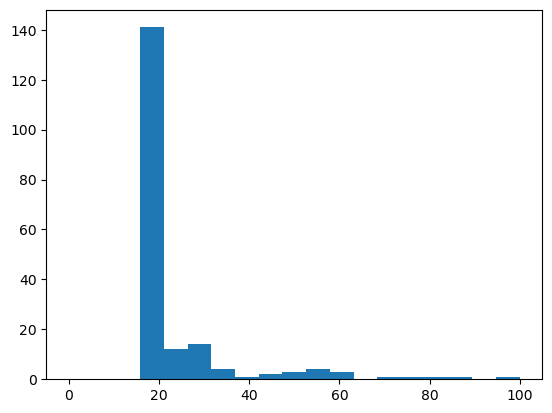

In [10]:
plt.hist(stat_radius_array_g[:,1], bins=np.linspace(0, 100, 20))
plt.show()

# Check the data

,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_MAG,3_XC,3_YC,3_MU_E,3_RE,3_N,3_MAG,4_XC,4_YC,4_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50,AIC_Rb,LIK_Rb,AIC_hRb,LIK_hRb
ssp_fo_p0m3,5.000000,1.000000,59.778700,60.752000,23.039500,10.528000,8.845100,17.488500,60.620900,63.999700,23.367400,19.938000,0.039000,18.363900,60.528500,62.660000,19.594600,8.013979,8.013979,112311.895913,0.000000,13.928596,107787.706815,0.000000,112311.895913,0.000000,109956.135109,0.000000
ssp_fo_p3p3,5.000000,1.000000,59.817600,60.753400,23.506300,13.188300,10.000000,17.376800,60.621600,64.031000,23.377700,20.802500,0.034800,18.313700,60.488800,62.820700,19.670200,8.014387,8.014387,112317.611861,0.000000,13.934005,107829.549506,0.000000,112317.611861,0.000000,109985.372781,0.000000
spp_fo_p0m3,6.000000,1.000000,60.440200,61.326500,22.905400,15.730800,1.205200,17.516500,60.465300,60.314000,nan,nan,nan,19.356300,59.528300,62.265600,19.181000,9.619655,9.619655,134837.871512,0.000000,16.829583,130289.023386,0.000000,134837.871512,0.000000,132462.353375,0.000000
spp_fo_p3m3,6.000000,0.000000,60.442000,61.519100,22.818900,15.398400,0.863600,17.629600,59.213900,61.716700,nan,nan,nan,18.946300,61.407400,60.625200,19.469000,9.539925,9.539925,133720.539209,0.000000,16.688189,129194.634062,0.000000,133720.539209,0.000000,131353.943084,0.000000
spp_fo_p3p3,6.000000,0.000000,60.609400,61.422600,22.841400,15.625900,1.041200,17.578100,60.490800,61.764800,nan,nan,nan,18.802200,58.241900,60.148800,19.907600,9.373587,9.373587,131389.480692,0.000000,16.391824,126900.774670,0.000000,131389.480692,0.000000,129045.767709,0.000000
ss_fo_p0m3,1.000000,0.000000,60.038500,61.351100,27.262200,121.000000,10.000000,16.241000,60.500000,60.500000,24.262200,10.000000,4.000000,18.782300,nan,nan,nan,18.005700,18.106365,253754.522674,0.000000,31.354848,242685.232317,0.000000,253754.522674,0.000000,249254.787857,0.000000
ss_fo_p0p3,1.000000,0.000000,60.038500,61.351100,27.262200,121.000000,10.000000,16.241000,60.500000,60.500000,30.262200,10.000000,4.000000,24.782300,nan,nan,nan,11.562160,29.051325,407126.255730,0.000000,51.320895,397202.467630,0.000000,407126.255730,0.000000,402954.296782,0.000000
ss_fo_p3m3,1.000000,0.000000,61.198300,61.542300,27.485400,121.000000,7.687800,17.232500,59.794600,61.259500,23.739300,13.676400,10.000000,17.173500,nan,nan,nan,9.966685,9.966686,139693.201970,0.000000,17.408343,134753.227168,0.000000,139693.201970,0.000000,137081.951234,0.000000
ss_fo_p3p3,1.000000,0.000000,60.038500,61.351100,30.262200,121.000000,10.000000,19.241000,60.500000,60.500000,30.262200,10.000000,4.000000,24.782300,nan,nan,nan,126.817400,132.580221,1857876.674691,0.000000,239.444830,1853093.603149,0.000000,1857876.674691,0.000000,1855458.003180,0.000000
sp_fo_p0m3,2.000000,0.000000,60.038500,61.351100,27.262200,121.000000,10.000000,16.241000,60.500000,60.500000,nan,nan,nan,24.262200,nan,nan,nan,11.556490,28.838050,404244.968543,0.000000,50.923894,394325.744450,0.000000,404244.968543,0.000000,400074.484913,0.000000


,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_AR,2_PA,2_MAG,3_XC,3_YC,3_MU_E,3_RE,3_N,3_AR,3_PA,3_MAG,4_XC,4_YC,4_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50,AIC_Rb,LIK_Rb,AIC_hRb,LIK_hRb
s_mo_m3,0.000000,0.000000,60.037800,61.348700,24.706600,32.727400,10.000000,0.725800,60.987900,16.514100,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,10.361720,10.361720,145287.329519,0.000000,18.141155,140537.401373,0.000000,145287.329519,0.000000,142722.072617,0.000000
ss_mo_m3m3,1.000000,0.000000,60.248100,63.580300,23.360400,20.655500,0.037600,0.551200,55.583100,18.344900,60.005800,61.323900,22.039700,6.113300,10.000000,0.814100,68.316700,17.365700,nan,nan,nan,8.233648,8.233648,115408.150588,0.000000,14.312105,110791.439307,0.000000,115408.150588,0.000000,112999.469030,0.000000
sp_mo_p3m3,2.000000,0.000000,60.204000,61.261400,23.046300,16.052100,2.139400,0.676800,60.655700,17.285700,59.962700,61.421100,nan,nan,nan,nan,nan,18.793900,nan,nan,nan,9.878198,9.878198,138484.717218,0.000000,17.272591,133763.703618,0.000000,138484.717218,0.000000,135978.598355,0.000000
p_fo_m3,3.000000,0.000000,60.019700,61.411600,nan,nan,nan,nan,nan,18.127900,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,43.873230,43.873230,615286.179524,0.000000,75.544750,585479.820379,0.000000,615286.179524,0.000000,599330.730835,0.000000
ssp_fo_p0m3,5.000000,1.000000,59.778700,60.752000,23.039500,10.528000,8.845100,0.654000,70.035600,17.488500,60.620900,63.999700,23.367400,19.938000,0.039000,0.585100,52.921400,18.363900,60.528500,62.660000,19.594600,8.013979,8.013979,112311.895913,0.000000,13.928596,107787.706815,0.000000,112311.895913,0.000000,109956.135109,0.000000
spp_fo_p3p3,6.000000,0.000000,60.609400,61.422600,22.841400,15.625900,1.041200,0.625400,58.973900,17.578100,60.490800,61.764800,nan,nan,nan,nan,nan,18.802200,58.241900,60.148800,19.907600,9.373587,9.373587,131389.480692,0.000000,16.391824,126900.774670,0.000000,131389.480692,0.000000,129045.767709,0.000000


./gal_out/gal0002/g_3comp_t/result_ssp_fo_p0m3.fits


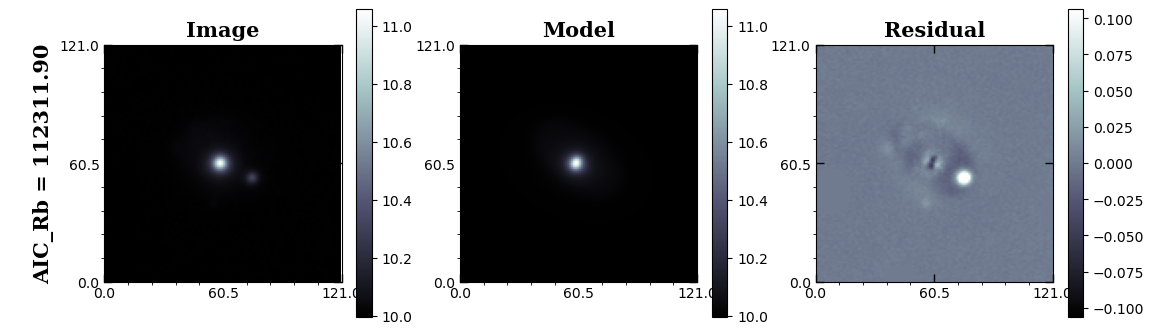

In [343]:
galid=2

ResGal=ResPack_g_3Comp_t.MC2fitSettingClass.result(galid=galid, group_id=None, comp_crit='AIC_hRb')
ResGal.show_data(only_val=True, hide_PA=True, hide_fail_read=True) ## Show the summary
ResBest=dhmc2fit.ResultBest(ResGal, include_warn=True, get_single=True)
ResBest.show_data(only_val=True, hide_PA=False) ## Show the summary (Only best result for each group)

# fn=ResGal.Data.fnlist[ResGal.best[0]] ## avoid warning results if possible 
fn=ResGal.Data.fnlist[ResGal.best_warn[0]]  ## Best results regardlenss of warning
print(fn)

ResPack_g_3Comp_t.MC2fitSettingClass.drawing(galid=galid, fn=fn)
plt.show()
# MC2_g_1comp_m.drawing_legacy(galid=galid)

# Classification

In [10]:
# class_list=['0: Sersic', '1: S+S', '2: S+PSF', '3: PSF', '4: 2comp', 
#             '5: far_comp', '6: dim_PSF', '7: Poor_L',
#             '11: SS+PSF', '12: S+2PSF', '13: 2PSF', '14: 2comp+PSF']

## Classification settings

`ClassResult` compares six model families:

| Model index | Name | Components |
|---:|---|---|
| 0 | `S` | one Sérsic component |
| 1 | `SS` | two Sérsic components |
| 2 | `SP` | one Sérsic component plus one PSF |
| 3 | `P` | one PSF |
| 4 | `SSP` | two Sérsic components plus one PSF |
| 5 | `SPP` | one Sérsic component plus two PSFs |

### Important parameters

- `ResPack`  
  The packed MC2fit result object containing all model groups and fitted parameters.

- `use_warn`  
  When `True`, warning-bearing fits may still be used. The class reads `bobwarn_onlyval` and the corresponding warning-inclusive submodel arrays.  
  When `False`, only the preferred warning-free results are used.

- `comp_crit`  
  The AIC field used to compare models. The corresponding likelihood field is generated automatically by replacing `AIC_` with `LIK_`.

  Common examples:

  - `AIC_hRb`: AIC measured within half of the reference effective radius.
  - `AIC_Rb`: AIC measured within the reference effective radius.
  - `AIC_50`: AIC measured within a 50-pixel-radius aperture.

- `aic_crit`  
  Maximum allowed difference from the minimum AIC for a model to remain competitive.  
  A model is retained when `AIC - minimum AIC <= aic_crit`.

- `likelihood_crit`  
  Models with likelihood below this threshold are removed before classification.  
  Set this to `0` to disable the likelihood rejection.

- `dim_psf`  
  PSF magnitude threshold reserved for identifying very faint PSF components. This parameter is stored by the class but is not currently applied in the shown classification logic.

### Model-selection logic

1. Remove models below `likelihood_crit`.
2. Find all models within `aic_crit` of the minimum AIC.
3. If only one model remains, select it.
4. If several models remain, prefer the smallest number of components.
5. If multiple equally simple models remain, select the one with the lowest AIC.


In [315]:
class ClassResult():
    def __init__(self, ResPack, 
                 use_warn=True, 
                 comp_crit='AIC_hRb',
                 aic_crit=11.83, 
                 likelihood_crit=0.1, 
                 dim_psf=24,
                ):
        """
        INPUT
         - ResPack : Result package
         * use_warn : If true, select the best result regardless of the warning (default: True)
         * comp_crit : The region for AIC calculation (default: 'AIC_hRb')
           - AIC_hRb: half Reff (from 1st fitting)
           - AIC_Rb: Reff (from 1st fitting)
           - AIC_50: 50-pixel-radius circle
         * aic_crit : AIC difference criterion. (default: 11.83)
           - if you want to use 3 sigma, use 11.83
           - if you want to use 2 sigma, use 6.18
         * likelihood_crit : Lower likelihood results will be classified as a failed-fitting group (default: 0.1)
         * dim_psf: if PSF is darker than the given value -> classfied as a dim_PSF group
         
        """
        ## Setting
        self.ResPack=ResPack       
        self.aic_crit=aic_crit
        self.comp_crit=comp_crit
        self.likelihood_crit=likelihood_crit
        self.dim_psf=dim_psf

        ## Update
        self.ResPack.update_comp_crit(self.comp_crit)
        self.ResPack.preset_generate_onlyval(submodel=-1, silent=True)


        ## Run
        self.extract_model(use_warn, comp_crit)
        self.check_fits()
        self.get_aic(comp_crit)
        self.classify()

        self.bobcl_aic_onlyval, self.bobcl_aic_onlyerr = self.assign_classi_result(self.classi_model_best_aic)
        self.bobcl_onlyval, self.bobcl_onlyerr = self.assign_classi_result(self.classi_model_final)

        
        # self.classify()
#         self.dist_cut=dist_cut

        # ## Bad likelihood -> New def
        # self.likelihood=self.bob_onlyval['LIK_'+aic_region]
        # target=np.where(self.bob_onlyval['LIK_'+aic_region] < likelihood_crit)[0]
        # self.classification[target]=7

        # dmu0_main=Sersic1D(amplitude=1, r_eff=1, n=self.bob_onlyval['2_N'])
        # dmu0_main=-2.5*np.log10(dmu0_main(0))
        # self.mu_0=self.bob_onlyval['2_MU_E']+dmu0_main

        # self.classification_ori=np.copy(self.bob_onlyval['group_ID']).astype(int) ## Original classification
        # self.classification=np.copy(self.bob_onlyval['group_ID']).astype(int) ## Classification  (no Sersic -> PSF conversion)

        
    def extract_model(self, use_warn, comp_crit):           
        for groupid in self.ResPack.groupid_list:
            if(hasattr(self.ResPack, "sub"+str(int(groupid))+"_onlyval")==False): 
                self.ResPack.preset_generate_onlyval(submodel=groupid)

        self.groupid_list = self.ResPack.groupid_list
        self.gid2submodel = np.full(np.nanmax(self.groupid_list)+1, np.nan) ## Group ID to submodel
        for i in range (len(self.gid2submodel)):
            thisloc = np.where(self.groupid_list==i)[0]
            if(len(thisloc)==1):
                self.gid2submodel[i]=thisloc[0]     ## self.gid2submodel[group_id] ==> corresponding submodel location
            
        # copy bob_onlyval
        if(use_warn): 
            self.bob_onlyval=np.copy(self.ResPack.bobwarn_onlyval)
            self.bob_onlyerr=np.copy(self.ResPack.bobwarn_onlyerr)
            text_onlyval= "warn_onlyval"
            text_onlyerr= "warn_onlyerr"
        else:
            self.bob_onlyval=np.copy(self.ResPack.bob_onlyval)
            self.bob_onlyerr=np.copy(self.ResPack.bob_onlyerr)
            text_onlyval= "_onlyval"
            text_onlyerr= "_onlyerr"
            
        self.subonlyval=np.zeros(len(self.groupid_list), dtype=object)
        self.subonlyerr=np.zeros(len(self.groupid_list), dtype=object)
        
        for i, groupid in enumerate (self.groupid_list):
            self.subonlyval[i]=copy.deepcopy(getattr(self.ResPack, "sub"+str(int(groupid))+text_onlyval))
            self.subonlyval[i][comp_crit][self.subonlyval[i][comp_crit]<0]=1e8-1 ## Strange results
            self.subonlyval[i][comp_crit][self.subonlyval[i]['war_tot']>=10]=1e8-1 ## Reff crit

            self.subonlyerr[i]=copy.deepcopy(getattr(self.ResPack, "sub"+str(int(groupid))+text_onlyerr))
            self.subonlyerr[i][comp_crit][self.subonlyerr[i][comp_crit]<0]=1e8-1 ## Strange results
            self.subonlyerr[i][comp_crit][self.subonlyerr[i]['war_tot']>=10]=1e8-1 ## Reff crit


    def check_fits(self):
        """
        Check fits and save the model code.
        """
        complist = self.ResPack.RunlistClass.runlist['complist']
        Ncomp = self.ResPack.RunlistClass.runlist['ncomp']
        Nfits = len(complist)

        ## Model code
        # 0 S
        # 1 SS
        # 2 SP
        # 3 P
        # 4 SSP
        # 5 SPP
        self.model_code_name = np.array(['s', 'ss', 'sp', 'p', 'ssp', 'spp'])
        self.model_Ncomp =  np.char.str_len(self.model_code_name)
        model_code = np.full(Nfits, np.nan)

        ## Number of each component
        Nfits_Nsersic2 = np.array([components.count('sersic2') for components in complist])
        Nfits_Nsersic = np.array([components.count('sersic') for components in complist])
        Nfits_Nsersic_tot = Nfits_Nsersic2 + Nfits_Nsersic
        Nfits_Npsf = np.array([components.count('psf') for components in complist])
        
        strange = np.where(Nfits_Nsersic2+Nfits_Npsf!=Ncomp)[0]
        if(len(strange)!=0):
            print("Warning! Some models are not PSF, Sersic, or Sersic2")
            print(strange)

        ## Assign submodel code
        target = (Ncomp==1) & (Nfits_Nsersic_tot==1)
        model_code[target]=0 # S
        target = (Ncomp==1) & (Nfits_Nsersic_tot==0)
        model_code[target]=3 # P
        
        target = (Ncomp==2) & (Nfits_Nsersic_tot==2)
        model_code[target]=1 # SS
        target = (Ncomp==2) & (Nfits_Nsersic_tot==1)
        model_code[target]=2 # SP
        
        target = (Ncomp==3) & (Nfits_Nsersic_tot==2)
        model_code[target]=4 # SSP
        target = (Ncomp==3) & (Nfits_Nsersic_tot==1)
        model_code[target]=5 # SPP
    
        self.model_code = model_code

        ## Validity check
        for groupid in self.ResPack.groupid_list:
            confirm_model = np.unique(self.model_code[self.ResPack.RunlistClass.runlist['group_ID']==groupid])
            if(len(confirm_model)>1): 
                print("Single group has two or more model code! Check group_ID of", groupid)

    def _return_best_array(self, comp_crit, thiscode=0):
        runlist_group_ID = self.ResPack.RunlistClass.runlist["group_ID"]
    
        if thiscode >= 0:
            indices_temp = np.unique(
                runlist_group_ID[self.model_code == thiscode]
            )
        else:
            indices_temp = np.unique(runlist_group_ID)
    
        # Convert the AIC field name to the corresponding likelihood field name
        if comp_crit.startswith("AIC_"):
            lik_crit = comp_crit.replace("AIC_", "LIK_", 1)
        else:
            raise ValueError(
                f"comp_crit must start with 'AIC_': {comp_crit}"
            )
    
        def make_nan_array(template):
            """
            Create a structured array filled with NaN.
    
            Integer fields are converted to float so that they can store NaN.
            Other field shapes are preserved.
            """
            new_dtype = []
    
            for name in template.dtype.names:
                field_dtype = template.dtype.fields[name][0]
    
                if field_dtype.subdtype is None:
                    base_dtype = field_dtype
                    field_shape = ()
                else:
                    base_dtype, field_shape = field_dtype.subdtype
    
                if np.issubdtype(base_dtype, np.number):
                    new_dtype.append((name, np.float64, field_shape))
                else:
                    new_dtype.append((name, object, field_shape))
    
            nan_array = np.empty(template.shape, dtype=new_dtype)
    
            for name in nan_array.dtype.names:
                nan_array[name] = np.nan
    
            return nan_array
    
        def return_nan_result():
            """
            Return empty results when no valid model is available.
            """
            nan_val_array = make_nan_array(self.bob_onlyval)
            nan_err_array = make_nan_array(self.bob_onlyerr)
    
            n_object = len(self.bob_onlyval)
    
            aic_value = np.full(n_object, np.nan)
            lik_value = np.full(n_object, np.nan)
            aic_group_id = np.full(n_object, np.nan)
    
            return (
                nan_val_array,
                nan_err_array,
                aic_value,
                lik_value,
                aic_group_id,
            )
    
        # Return NaN arrays if the requested model type does not exist
        if len(indices_temp) == 0:
            return return_nan_result()
    
        # Keep only group IDs that have a valid submodel mapping
        valid_group_mask = (
            (indices_temp >= 0)
            & (indices_temp < len(self.gid2submodel))
        )
        indices_temp = indices_temp[valid_group_mask]
    
        if len(indices_temp) == 0:
            return return_nan_result()
    
        mapped_indices = self.gid2submodel[indices_temp]
        valid_mapping_mask = np.isfinite(mapped_indices)
    
        indices_temp = indices_temp[valid_mapping_mask]
        indices = mapped_indices[valid_mapping_mask].astype(int)
    
        if len(indices) == 0:
            return return_nan_result()
    
        # Keep only submodels with available value and error arrays
        valid_submodel_mask = np.array([
            (
                0 <= i < len(self.subonlyval)
                and 0 <= i < len(self.subonlyerr)
                and self.subonlyval[i] is not None
                and self.subonlyerr[i] is not None
                and hasattr(self.subonlyval[i], "dtype")
                and hasattr(self.subonlyerr[i], "dtype")
                and self.subonlyval[i].dtype.names is not None
                and self.subonlyerr[i].dtype.names is not None
                and comp_crit in self.subonlyval[i].dtype.names
                and lik_crit in self.subonlyval[i].dtype.names
            )
            for i in indices
        ])
    
        indices_temp = indices_temp[valid_submodel_mask]
        indices = indices[valid_submodel_mask]
    
        if len(indices) == 0:
            return return_nan_result()
    
        # Stack the comparison criterion for all selected models
        crit_stack = np.stack([
            self.subonlyval[i][comp_crit]
            for i in indices
        ])
    
        # Check whether each object has at least one finite criterion value
        has_valid_model = np.any(np.isfinite(crit_stack), axis=0)
    
        # Replace invalid values temporarily to avoid nanargmin errors
        crit_stack_safe = np.where(
            np.isfinite(crit_stack),
            crit_stack,
            np.inf,
        )
    
        # Find the minimum criterion value and the corresponding model
        arg_temp = np.argmin(crit_stack_safe, axis=0)
        aic_value = np.min(crit_stack_safe, axis=0)
    
        # Set objects without any valid model to NaN
        aic_value[~has_valid_model] = np.nan
    
        # Stack the full value and error arrays
        val_stack = np.stack([
            self.subonlyval[i]
            for i in indices
        ])
    
        err_stack = np.stack([
            self.subonlyerr[i]
            for i in indices
        ])
    
        object_index = np.arange(val_stack.shape[1])
    
        # Select the full value and error rows from the best model
        best_array = val_stack[arg_temp, object_index].copy()
        best_err_array = err_stack[arg_temp, object_index].copy()
    
        # Extract the likelihood value from the selected model
        lik_value = np.asarray(
            best_array[lik_crit],
            dtype=float,
        ).copy()
    
        # Return the group ID of the selected model
        aic_group_id = indices_temp[arg_temp].astype(float)
    
        # Replace objects without any valid model with NaN rows
        if np.any(~has_valid_model):
            best_array_converted = make_nan_array(best_array)
            best_err_array_converted = make_nan_array(best_err_array)
    
            for name in best_array.dtype.names:
                best_array_converted[name][has_valid_model] = \
                    best_array[name][has_valid_model]
    
            for name in best_err_array.dtype.names:
                best_err_array_converted[name][has_valid_model] = \
                    best_err_array[name][has_valid_model]
    
            best_array = best_array_converted
            best_err_array = best_err_array_converted
    
            lik_value[~has_valid_model] = np.nan
            aic_group_id[~has_valid_model] = np.nan
    
        return (
            best_array,
            best_err_array,
            aic_value,
            aic_group_id,
            lik_value
        )
    
    def get_aic(self, comp_crit):
        ## Model code
        # 0 S
        # 1 SS
        # 2 SP
        # 3 P
        # 4 SSP
        # 5 SPP
        self.bob_s_onlyval, self.bob_s_onlyerr, self.aic_s, self.aic_s_gID, self.lik_s = self._return_best_array(comp_crit, thiscode=0)
        self.bob_ss_onlyval, self.bob_ss_onlyerr, self.aic_ss, self.aic_ss_gID, self.lik_ss = self._return_best_array(comp_crit, thiscode=1)
        self.bob_sp_onlyval, self.bob_sp_onlyerr, self.aic_sp, self.aic_sp_gID, self.lik_sp = self._return_best_array(comp_crit, thiscode=2)
        self.bob_p_onlyval, self.bob_p_onlyerr, self.aic_p, self.aic_p_gID, self.lik_p = self._return_best_array(comp_crit, thiscode=3)
        self.bob_ssp_onlyval, self.bob_ssp_onlyerr, self.aic_ssp, self.aic_ssp_gID, self.lik_ssp = self._return_best_array(comp_crit, thiscode=4)
        self.bob_spp_onlyval, self.bob_spp_onlyerr, self.aic_spp, self.aic_spp_gID, self.lik_spp = self._return_best_array(comp_crit, thiscode=5)
        self.bob_best_onlyval, self.bob_best_onlyerr, self.aic_best, self.aic_best_gID, self.lik_best = self._return_best_array(comp_crit, thiscode=-1)

        self.aic_table_orig = np.stack((self.aic_s, self.aic_ss, self.aic_sp, self.aic_p, self.aic_ssp, self.aic_spp)).T
        self.lik_table = np.stack((self.lik_s, self.lik_ss, self.lik_sp, self.lik_p, self.lik_ssp, self.lik_spp)).T
        self.aic_table = copy.deepcopy(self.aic_table_orig)
        self.aic_table[self.lik_table<self.likelihood_crit]=np.nan
        self.aic_order = np.argsort(self.aic_table, axis=1) ## argsort order
        
        


    def classify(self):
        ## Best model regardless of checking Delta AIC
        self.classi_model_best_aic = copy.deepcopy(self.aic_order[:,0])
        
        ## All values exceed delta AIC (aic_crit) --> Nan
        aic_delta = self.aic_table - np.nanmin(self.aic_table, axis=1, keepdims=True)
        aic_delta[aic_delta>self.aic_crit]=np.nan
        self.classi_aic_delta=aic_delta
        self.classi_Ncompeting_aic = np.sum(np.isfinite(self.classi_aic_delta), axis=1)  ## number of competing AIC models
        

        ## If classi_Ncompeting_aic == 1, That is the best model
        self.classi_model_final = np.full(len(self.aic_s), np.nan)
        self.classi_model_final[self.classi_Ncompeting_aic==1] = self.aic_order[:,0][self.classi_Ncompeting_aic==1] ## Lowest one

        ## If classi_Ncompeting_aic > 1, check Ncomp.
        check_Ncomp = np.repeat(self.model_Ncomp[None, :], len(self.aic_s), axis=0).astype(float) ## (Ngal, Nmodel)
        check_Ncomp[np.isnan(self.classi_aic_delta)]=np.nan
        min_Ncomp = np.nanmin(check_Ncomp, axis=1)
        model_min_Ncomp = np.sum(check_Ncomp == min_Ncomp[:, None], axis=1)
        is_min = np.isclose(check_Ncomp, min_Ncomp[:, None], equal_nan=False)
        
        self.classi_Ncompeting_aic_comp = copy.deepcopy(model_min_Ncomp) ## number of competing AIC models w/ min Ncomp
        
        ##  -- If there is only one model with min N comp,  there is only one simplest model. Use that
        target = (np.isnan(self.classi_model_final)) & (model_min_Ncomp==1)        
        self.classi_model_final[target] = self.aic_order[target][is_min[target]]        

        ## -- If there are multiple models with min N comp, those are competing models. 
        ## -- classi_Ncompeting_aic_comp > 1 for those.
        ## For now, use the lowest AIC among them.
        
        target = self.classi_Ncompeting_aic_comp>1  
        filtered_aic_table = self.aic_table[target]
        filtered_aic_table[is_min[target]==False]=np.nan ## Only models w/ min comp
        filtered_aic_order = np.argsort(filtered_aic_table, axis=1) ## argsort order
        self.classi_model_final[target] = filtered_aic_order[:,0]

        ## Classification - mark if the fit has competitions

        self.classification = copy.deepcopy(self.classi_model_final)
        self.classification[np.isnan(self.classification)]=99
        self.classification=self.classification.astype(int)
        target_Ncomp1 = (self.classi_Ncompeting_aic_comp>1) & (min_Ncomp==1)
        self.classification[target_Ncomp1]=11
        target_Ncomp1 = (self.classi_Ncompeting_aic_comp>1) & (min_Ncomp==2)
        self.classification[target_Ncomp1]=12
        target_Ncomp1 = (self.classi_Ncompeting_aic_comp>1) & (min_Ncomp==3)
        self.classification[target_Ncomp1]=13

    def assign_classi_result(self, index):
        """
        Select the value and error arrays corresponding to the model index
        assigned to each object.
    
        Model indices:
            0: S
            1: SS
            2: SP
            3: P
            4: SSP
            5: SPP
        """
        index = np.asarray(index).reshape(-1)
    
        # Identify non-finite, non-integer, and out-of-range indices
        invalid = (
            ~np.isfinite(index)
            | (index < 0)
            | (index >= 6)
            | (index != np.floor(index))
        )
    
        # Use zero as a temporary valid index for array selection
        index_safe = index.copy()
        index_safe[invalid] = 0
        index_safe = index_safe.astype(int)
    
        data_stack = np.stack([
            self.bob_s_onlyval,    # 0: S
            self.bob_ss_onlyval,   # 1: SS
            self.bob_sp_onlyval,   # 2: SP
            self.bob_p_onlyval,    # 3: P
            self.bob_ssp_onlyval,  # 4: SSP
            self.bob_spp_onlyval,  # 5: SPP
        ])
    
        err_stack = np.stack([
            self.bob_s_onlyerr,    # 0: S
            self.bob_ss_onlyerr,   # 1: SS
            self.bob_sp_onlyerr,   # 2: SP
            self.bob_p_onlyerr,    # 3: P
            self.bob_ssp_onlyerr,  # 4: SSP
            self.bob_spp_onlyerr,  # 5: SPP
        ])
    
        n_object = data_stack.shape[1]
    
        if len(index_safe) != n_object:
            raise ValueError(
                f"index contains {len(index_safe)} entries, "
                f"but the result arrays contain {n_object} objects."
            )
    
        object_index = np.arange(n_object)
    
        # Select the value and error rows for each object
        selected_onlyval = data_stack[
            index_safe,
            object_index,
        ].copy()
    
        selected_onlyerr = err_stack[
            index_safe,
            object_index,
        ].copy()
    
        # Assign missing values to objects with invalid model indices
        selected_onlyval = self._set_invalid_rows(
            selected_onlyval,
            invalid,
        )
    
        selected_onlyerr = self._set_invalid_rows(
            selected_onlyerr,
            invalid,
        )
    
        return selected_onlyval, selected_onlyerr

    def _set_invalid_rows(self, array, invalid):
        # Assign dtype-compatible missing values
        for field_name in array.dtype.names:
            field_dtype = array.dtype[field_name]
    
            if np.issubdtype(field_dtype, np.floating):
                array[field_name][invalid] = np.nan
    
            elif np.issubdtype(field_dtype, np.integer):
                array[field_name][invalid] = -1
    
            elif np.issubdtype(field_dtype, np.bool_):
                array[field_name][invalid] = False
    
            elif np.issubdtype(field_dtype, np.str_):
                array[field_name][invalid] = ""
    
        return array

In [344]:
# Run the classification for all galaxies.
# Set likelihood_crit=0 to keep every model regardless of likelihood.
Classi = ClassResult(
    ResPack_g_3Comp_t,
    use_warn=True,
    comp_crit="AIC_hRb",
    aic_crit=11.83,
    likelihood_crit=0,
)


>> Updated comp_crit: AIC_hRb
>> Regenerated best_index, bestwarn_index, bob_index, and bobwarn_index and all bob/submodel onlyval arrays


/tmp/ipykernel_56610/1452029108.py:374: RuntimeWarning: All-NaN slice encountered
  aic_delta = self.aic_table - np.nanmin(self.aic_table, axis=1, keepdims=True)
/tmp/ipykernel_56610/1452029108.py:387: RuntimeWarning: All-NaN slice encountered
  min_Ncomp = np.nanmin(check_Ncomp, axis=1)


## Running the classification

```python
Classi = ClassResult(
    ResPack_g_3Comp_t,
    use_warn=True,
    comp_crit="AIC_hRb",
    aic_crit=11.83,
    likelihood_crit=0,
)
```

## Most useful output arrays

All arrays below contain one entry per galaxy.

### Final classification

```python
Classi.classification
```

Classification codes:

| Code | Meaning |
|---:|---|
| 0 | unique preferred `S` model |
| 1 | unique preferred `SS` model |
| 2 | unique preferred `SP` model |
| 3 | unique preferred `P` model |
| 4 | unique preferred `SSP` model |
| 5 | unique preferred `SPP` model |
| 11 | multiple competitive one-component models |
| 12 | multiple competitive two-component models |
| 13 | multiple competitive three-component models |
| 99 | no valid model remained |

### Selected model index

```python
Classi.classi_model_final
```

This stores the final selected model index from 0 to 5. Invalid objects remain `NaN`.

```python
Classi.classi_model_best_aic
```

This stores the model with the lowest AIC before applying the simplicity preference.

### Selected fitting results

```python
Classi.bobcl_onlyval
Classi.bobcl_onlyerr
```

These are the fitted values and uncertainties corresponding to `classi_model_final`.

```python
Classi.bobcl_aic_onlyval
Classi.bobcl_aic_onlyerr
```

These correspond to the model with the absolute minimum AIC, before the competing-model and component-count logic.

Examples:

```python
# Effective radius of component 2
reff = Classi.bobcl_onlyval["2_RE"]
reff_err = Classi.bobcl_onlyerr["2_RE"]

# Sérsic index of component 2
sersic_n = Classi.bobcl_onlyval["2_N"]

# Group ID selected for each galaxy
group_id = Classi.bobcl_onlyval["group_ID"]
```

Use the field names available in the structured array:

```python
Classi.bobcl_onlyval.dtype.names
```

### AIC and likelihood tables

```python
Classi.aic_table_orig
Classi.lik_table
```

Both have shape `(N_galaxy, 6)`, with columns ordered as:

```python
["S", "SS", "SP", "P", "SSP", "SPP"]
```

- `aic_table_orig`: best AIC value within each model family.
- `lik_table`: likelihood associated with the same selected fit.
- `aic_table`: AIC table after models below `likelihood_crit` are set to `NaN`.
- `aic_order`: model indices sorted from lowest to highest AIC for each galaxy.
- `classi_aic_delta`: delta-AIC table after models outside `aic_crit` are set to `NaN`.
- `classi_Ncompeting_aic`: number of models remaining within the delta-AIC threshold.
- `classi_Ncompeting_aic_comp`: number of competing models with the minimum component count.

### Results for a specific model family

```python
Classi.bob_s_onlyval
Classi.bob_ss_onlyval
Classi.bob_sp_onlyval
Classi.bob_p_onlyval
Classi.bob_ssp_onlyval
Classi.bob_spp_onlyval
```

The matching uncertainty arrays use `_onlyerr`, for example:

```python
Classi.bob_sp_onlyerr
```

The corresponding best AIC and likelihood arrays are:

```python
Classi.aic_s
Classi.lik_s

Classi.aic_ss
Classi.lik_ss
```

The same naming pattern applies to `sp`, `p`, `ssp`, and `spp`.


In [345]:
Classi.bob_s_onlyval

array([( 1, 57.7432, 58.2159, 22.5418,  21.6574,  3.2903,  0.624 ,  35.3609, 15.9978, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,  2.184558e+00,  2.18455793e+00,  3.19826460e+04,  0.00000000e+00,  3.41190963e+00,  2.67551541e+04,  0.00000000e+00,  1.76500312e+04,  0.00000000e+00, 1.14174983e+04,  0.00000000e+00,   0.,  0.,  0.),
       ( 1, 62.2927, 62.0155, 23.0182,  29.9563,  6.0991,  0.4517, -88.9577, 15.7963, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,  1.874349e+00,  1.87434856e+00,  2.68641788e+04,  0.00000000e+00,  2.66848346e+00,  2.05686783e+04,  0.00000000e+00,  1.43648900e+04,  0.00000000e+00, 4.69144820e+03,  0.00000000e+00,   0.,  0.,  0.),
       ( 1, 60.0378, 61.3487, 24.7066,  32.7274, 10.    ,  0.7258,  60.9879, 16.5141, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,  1.036172e+01,  1.03617203e+01,  1.45287330e+05,  0.00000000e+00,  1.81411545e+01,  1.40537401e+05, 

In [346]:
Classi.bobcl_onlyval

array([( 1, 57.7321, 58.4202, 20.1855,   3.1555,  0.6597, 0.912 ,  8.06122e+01, 18.1916, 57.7949, 57.9262,  22.458 ,  21.671 ,  1.5395, 0.5742,  3.41772e+01,  16.3888, 65.1406, 54.95  , nan, nan, nan, nan, nan,  22.8376, 9.453453e-01, 9.45345354e-01, 1.38598319e+04, 9.99999020e-01, 1.09427823e+00, 8.60100312e+03, 5.10009757e-09, 2.52942849e+03, 0.00000000e+00, 7.97557300e+02, 0.00000000e+00,  0.,  0.,  5.),
       ( 1, 62.3242, 61.8024, 22.1915,  22.2717,  0.8035, 0.3782, -8.90552e+01, 16.8236, 62.2967, 62.124 ,  19.2921,   2.9151,  1.8014, 0.6005, -8.85824e+01,  17.4524, 62.4002, 58.9932, nan, nan, nan, nan, nan,  21.8243, 1.080951e+00, 1.08095100e+00, 1.55087804e+04, 1.22976074e-11, 1.37460022e+00, 1.06095138e+04, 0.00000000e+00, 6.53897465e+03, 0.00000000e+00, 1.25006128e+03, 0.00000000e+00,  0.,  0.,  5.),
       ( 1, 60.6209, 63.9997, 23.3674,  19.938 ,  0.039 , 0.5851,  5.29214e+01, 18.3639, 59.7787, 60.752 ,  23.0395,  10.528 ,  8.8451, 0.654 ,  7.00356e+01,  17.4885, 60.5285, 6

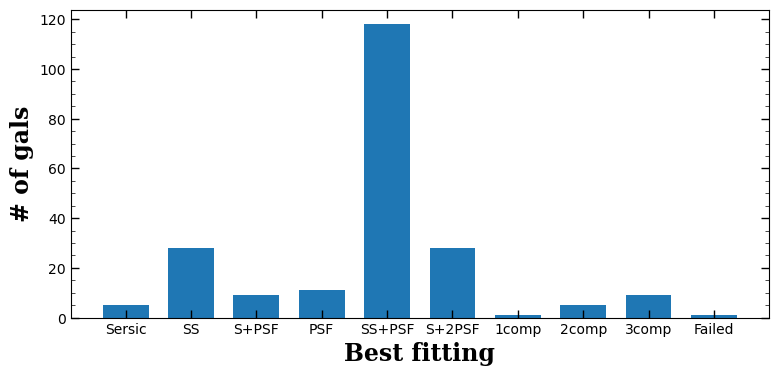

In [339]:
classes = np.array([0, 1, 2, 3, 4, 5, 11, 12, 13, 99])
counts = [np.sum(Classi.classification == x) for x in classes]

fig = plt.figure(figsize=(9,4))
gs = gridspec.GridSpec(1,1)
ax0 = plt.subplot(gs[0])

ax0.bar(np.arange(len(classes)), counts, width=0.7)

plt.xlabel("Best fitting", fontsize=17, fontname='DejaVu Serif', fontweight='semibold')
plt.ylabel(r"# of gals", fontsize=17, fontname='DejaVu Serif', fontweight='semibold')

plt.tick_params(labelsize=10, width=1, length=6, axis='both',
                direction='in', right=True, top=True)
plt.tick_params(width=0.5, length=3, which='minor', axis='both',
                direction='in', right=True, top=True)

ax0.set_xticks(np.arange(len(classes)))
ax0.set_xticklabels([
    'Sersic', 'SS', 'S+PSF', 'PSF',
    'SS+PSF', 'S+2PSF', '1comp', '2comp', '3comp', 'Failed'
])

ax0.yaxis.set_minor_locator(AutoMinorLocator(4))